<a href="https://colab.research.google.com/github/DalilaGallegos/Portafolio-Diplomado-en-Python-Gallegos-Jimenez-Yajaira-Dalila/blob/main/03_Clasificacion_Imagenes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DIPLOMADO: PROGRAMACIÓN EN PYTHON PARA LA WEB Y EL ANÁLISIS DE DATOS

## Portafolio de Evidencias de Aprendizaje

### Notebook 3. Clasificación de imágenes mediante Redes Neuronales Convolucionales

**Proyecto:** Clasificación automática de imágenes de objetos mediante una Red Neuronal Convolucional  
**Conjunto de datos:** CIFAR-10  
**Metodología:** CRISP-DM  
**Tipo de problema:** Clasificación multiclase  
**Modelo:** Red Neuronal Convolucional (CNN)  
**Número de clases:** 10

**Nombre del estudiante:** Yajaira Dalila Gallegos Jiménez

# Introducción

La clasificación automática de imágenes constituye una de las aplicaciones más conocidas del aprendizaje profundo. A diferencia de los conjuntos de datos tabulares, donde cada registro se representa mediante diferentes variables, en un problema de visión por computadora la información se encuentra contenida en los píxeles que forman una imagen.

Para desarrollar este proyecto se utilizará **CIFAR-10**, un conjunto de datos diseñado para tareas de clasificación de imágenes. Contiene 60,000 imágenes a color de 32 × 32 píxeles distribuidas en diez categorías diferentes: avión, automóvil, ave, gato, venado, perro, rana, caballo, barco y camión.

El proyecto se desarrollará siguiendo cinco fases de la metodología CRISP-DM: Comprensión del problema, Comprensión de los datos, Preparación de los datos, Modelado y Evaluación.

Para realizar la clasificación se utilizará una **Red Neuronal Convolucional (CNN)** construida mediante TensorFlow y Keras. Este tipo de red está especialmente diseñado para trabajar con imágenes, ya que sus capas convolucionales pueden aprender características visuales como bordes, formas, texturas y patrones más complejos.

Finalmente, el modelo será evaluado mediante imágenes que no participaron en su entrenamiento. Se analizarán métricas como Accuracy y Loss, se generará una matriz de confusión y se mostrarán ejemplos de imágenes clasificadas correcta e incorrectamente.

# Objetivo

Desarrollar una Red Neuronal Convolucional mediante TensorFlow/Keras para clasificar automáticamente imágenes del conjunto de datos CIFAR-10 en una de diez categorías posibles, aplicando las cinco fases de trabajo de la metodología CRISP-DM.

El proyecto incluirá la exploración y preparación de las imágenes, construcción y entrenamiento de la red neuronal, evaluación mediante datos de prueba e interpretación de los resultados obtenidos.

# 1. Comprensión del problema

## 1.1 Descripción del problema

El reconocimiento automático de objetos en imágenes es un problema de clasificación en el que un sistema debe analizar la información visual presente en una imagen y determinar a qué categoría pertenece.

En este proyecto se trabajará con imágenes pequeñas de diferentes objetos. Cada imagen pertenece únicamente a una de diez categorías:

- Avión
- Automóvil
- Ave
- Gato
- Venado
- Perro
- Rana
- Caballo
- Barco
- Camión

El problema consiste en desarrollar un modelo capaz de recibir una imagen y clasificarla correctamente dentro de una de estas diez categorías.

Debido a que existen más de dos posibles clases de salida, este proyecto corresponde a un problema de **clasificación multiclase**.

## 1.2 Importancia del reconocimiento automático de imágenes

La clasificación automática de imágenes tiene aplicaciones en diferentes áreas.

Los sistemas de visión por computadora pueden utilizarse para reconocer productos, analizar imágenes médicas, identificar especies de animales o plantas, detectar objetos en sistemas de transporte, organizar fotografías y automatizar procesos industriales.

La capacidad de una computadora para reconocer objetos no se obtiene programando manualmente todas las posibles formas de un objeto. En cambio, mediante aprendizaje profundo es posible utilizar grandes cantidades de imágenes para que una red neuronal aprenda patrones visuales relacionados con cada categoría.

CIFAR-10 proporciona un problema controlado que permite comprender los fundamentos de este proceso antes de trabajar con aplicaciones de mayor tamaño y complejidad.

## 1.3 Objetivo del proyecto

Construir, entrenar y evaluar una Red Neuronal Convolucional capaz de analizar imágenes del conjunto CIFAR-10 y clasificarlas automáticamente en una de sus diez categorías.

## 1.4 Resultados esperados

Se espera obtener un modelo capaz de aprender características visuales a partir de las imágenes de entrenamiento y posteriormente utilizar ese aprendizaje para clasificar imágenes que no fueron utilizadas durante dicho proceso.

Los resultados serán analizados mediante:

- Accuracy de entrenamiento, validación y prueba.
- Loss durante el proceso de aprendizaje.
- Matriz de confusión.
- Métricas individuales para las diferentes clases.
- Ejemplos de imágenes correctamente clasificadas.
- Ejemplos de imágenes clasificadas incorrectamente.

El objetivo no será únicamente obtener una métrica elevada, sino comprender el funcionamiento del modelo e interpretar sus principales aciertos, errores y limitaciones.

# 2. Comprensión de los datos

En esta fase se cargará y explorará CIFAR-10 para conocer la cantidad de imágenes, sus dimensiones, tipos de datos, etiquetas y distribución de clases.

También se visualizarán diferentes ejemplos con la finalidad de comprender el tipo de información que deberá procesar la red neuronal.

## 2.1 Importación de librerías

Para desarrollar el proyecto se utilizarán principalmente:

- **NumPy:** operaciones con arreglos numéricos.
- **Pandas:** organización de algunos resultados.
- **Matplotlib:** visualización de imágenes y gráficas.
- **Seaborn:** visualización de la matriz de confusión.
- **TensorFlow/Keras:** construcción y entrenamiento de la Red Neuronal Convolucional.
- **Scikit-learn:** división de los datos y evaluación del modelo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

## 2.2 Configuración para reproducibilidad

Se establecerá una semilla para NumPy y TensorFlow.

Esto permite reducir las variaciones entre diferentes ejecuciones del notebook, aunque algunos procesos de entrenamiento pueden seguir presentando pequeñas diferencias dependiendo del hardware utilizado.

In [2]:
np.random.seed(42)
tf.random.set_seed(42)

print("Versión de TensorFlow:", tf.__version__)

Versión de TensorFlow: 2.21.0


## 2.3 Verificación del entorno de ejecución

TensorFlow puede utilizar una GPU para acelerar el entrenamiento de redes neuronales.

La siguiente celda permitirá verificar si Google Colab tiene disponible este tipo de acelerador.

El proyecto también puede ejecutarse utilizando CPU, aunque el entrenamiento podría tardar más tiempo.

In [3]:
gpu = tf.config.list_physical_devices("GPU")

if gpu:
    print("GPU disponible:")
    print(gpu)
else:
    print("No se detectó GPU. El entrenamiento utilizará CPU.")

GPU disponible:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2.4 Carga del conjunto de datos CIFAR-10

CIFAR-10 se encuentra integrado dentro de los conjuntos de datos disponibles en Keras.

Por esta razón, no es necesario descargar manualmente las imágenes ni almacenarlas en Google Drive.

La función `cifar10.load_data()` descarga automáticamente el conjunto y devuelve:

- Imágenes de entrenamiento.
- Etiquetas de entrenamiento.
- Imágenes de prueba.
- Etiquetas de prueba.

In [4]:
from tensorflow.keras.datasets import cifar10

(X_train_full, y_train_full), (X_test, y_test) = cifar10.load_data()

print("CIFAR-10 cargado correctamente.")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2930s 17us/step
CIFAR-10 cargado correctamente.


## 2.5 Dimensiones del conjunto de datos

Se revisarán las dimensiones de los arreglos obtenidos.

In [5]:
print("X_train_full:", X_train_full.shape)
print("y_train_full:", y_train_full.shape)

print("\nX_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train_full: (50000, 32, 32, 3)
y_train_full: (50000, 1)

X_test: (10000, 32, 32, 3)
y_test: (10000, 1)


CIFAR-10 contiene:

- **50,000 imágenes de entrenamiento**.
- **10,000 imágenes de prueba**.

Cada imagen posee dimensiones de:

**32 × 32 × 3**

Los primeros dos valores corresponden al ancho y alto de la imagen.

El tercer valor representa sus tres canales de color:

- Rojo (R)
- Verde (G)
- Azul (B)

Por esta razón, cada imagen contiene información en formato RGB.

## 2.6 Tipos de datos y rango de los píxeles

Antes de preparar las imágenes se revisará el tipo de dato utilizado y el rango de valores de los píxeles.

In [6]:
print("Tipo de dato de las imágenes:")
print(X_train_full.dtype)

print("\nValor mínimo:")
print(X_train_full.min())

print("\nValor máximo:")
print(X_train_full.max())

Tipo de dato de las imágenes:
uint8

Valor mínimo:
0

Valor máximo:
255


Las imágenes se encuentran almacenadas originalmente como valores enteros de 8 bits (`uint8`).

Cada componente de color de un píxel puede tomar valores entre:

**0 y 255**

Un valor cercano a 0 representa una intensidad baja del canal correspondiente, mientras que un valor cercano a 255 representa una intensidad alta.

Antes del entrenamiento estos valores serán normalizados al intervalo entre 0 y 1.

## 2.7 Categorías de CIFAR-10

Las etiquetas originales utilizan valores numéricos entre 0 y 9.

Para facilitar la interpretación se crearán nombres en español para cada categoría.

In [8]:
nombres_clases = [
    "Avión",
    "Automóvil",
    "Ave",
    "Gato",
    "Venado",
    "Perro",
    "Rana",
    "Caballo",
    "Barco",
    "Camión"
]

for etiqueta, clase in enumerate(nombres_clases):
    print(f"{etiqueta}: {clase}")

0: Avión
1: Automóvil
2: Ave
3: Gato
4: Venado
5: Perro
6: Rana
7: Caballo
8: Barco
9: Camión


## 2.8 Ajuste de la forma de las etiquetas

Las etiquetas fueron cargadas con dimensiones `(n, 1)`.

Para facilitar los análisis posteriores se convertirán a arreglos unidimensionales.

In [9]:
y_train_full = y_train_full.flatten()
y_test = y_test.flatten()

print("Nueva forma de y_train_full:", y_train_full.shape)
print("Nueva forma de y_test:", y_test.shape)

Nueva forma de y_train_full: (50000,)
Nueva forma de y_test: (10000,)


## 2.9 Visualización de ejemplos

A continuación se mostrarán diferentes imágenes de CIFAR-10 junto con la categoría correspondiente.

Debido a que cada imagen tiene únicamente 32 × 32 píxeles, algunas pueden observarse poco definidas al ampliarlas. Esta baja resolución también hace que la clasificación sea más difícil.

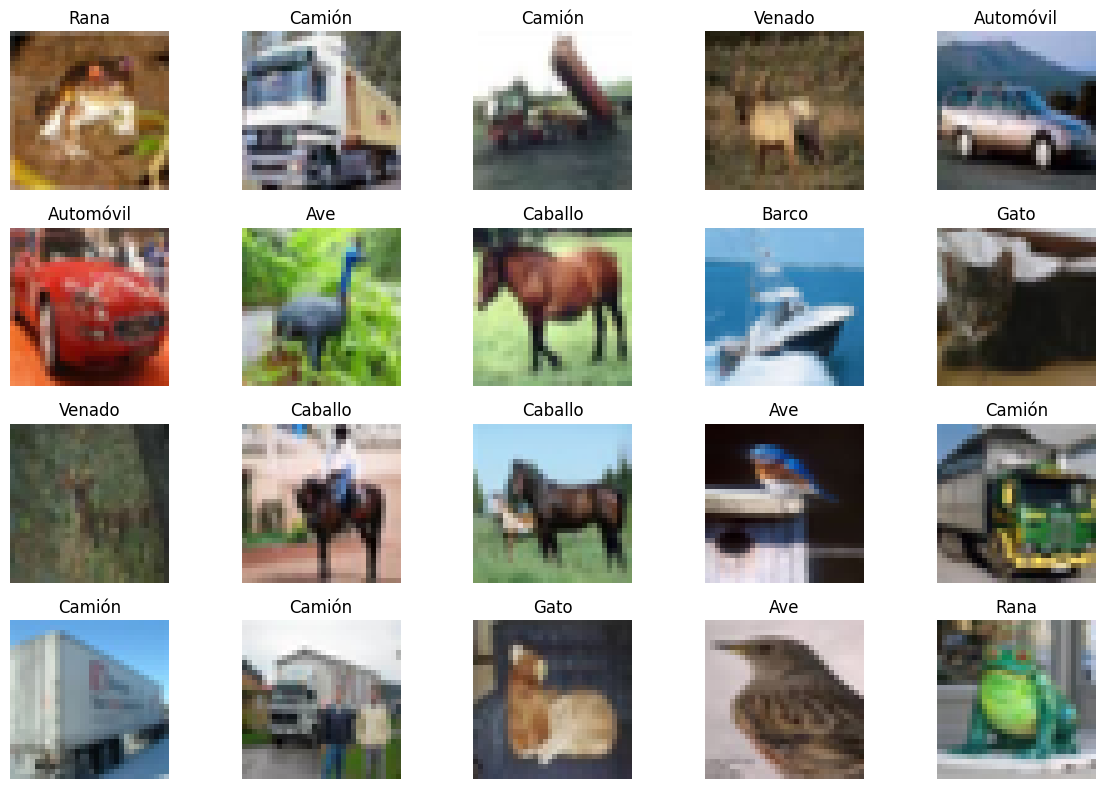

In [10]:
plt.figure(figsize=(12, 8))

for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(X_train_full[i])
    plt.title(nombres_clases[y_train_full[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

Las imágenes muestran que el conjunto contiene objetos con diferentes colores, fondos, posiciones y formas.

También puede observarse que algunas imágenes pertenecientes a categorías diferentes pueden presentar características visuales similares.

Por ejemplo, distinguir entre un gato y un perro puede resultar más complicado que diferenciar un automóvil de un avión.

Esto permite anticipar que algunas clases podrían presentar mayores dificultades durante la clasificación.

## 2.10 Distribución de las clases

Antes de entrenar la red neuronal es importante comprobar la cantidad de imágenes pertenecientes a cada categoría.

Un conjunto fuertemente desbalanceado podría provocar que el modelo aprendiera con mayor facilidad las clases más frecuentes.

In [11]:
conteos_train = np.bincount(
    y_train_full,
    minlength=10
)

conteos_test = np.bincount(
    y_test,
    minlength=10
)

distribucion = pd.DataFrame({
    "Clase": nombres_clases,
    "Entrenamiento": conteos_train,
    "Prueba": conteos_test
})

distribucion

,Clase,Entrenamiento,Prueba
0,Avión,5000,1000
1,Automóvil,5000,1000
2,Ave,5000,1000
3,Gato,5000,1000
4,Venado,5000,1000
5,Perro,5000,1000
6,Rana,5000,1000
7,Caballo,5000,1000
8,Barco,5000,1000
9,Camión,5000,1000


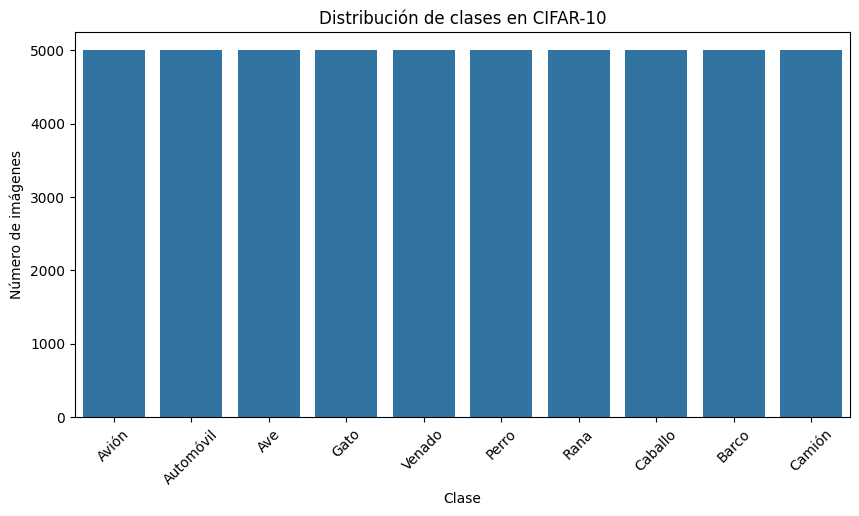

In [12]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=distribucion,
    x="Clase",
    y="Entrenamiento"
)

plt.title("Distribución de clases en CIFAR-10")
plt.xlabel("Clase")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=45)

plt.show()

Las diez clases presentan la misma cantidad de imágenes.

Cada categoría contiene:

- **5,000 imágenes de entrenamiento.**
- **1,000 imágenes de prueba.**

Por lo tanto, CIFAR-10 se encuentra balanceado respecto a sus clases.

Esto representa una ventaja durante el entrenamiento y permite utilizar Accuracy como una métrica general de desempeño sin el problema de un desbalance importante entre categorías.

# 3. Preparación de los datos

Las imágenes deben prepararse antes de ser procesadas por la red neuronal.

En esta fase se realizarán principalmente dos actividades:

1. División del conjunto original de entrenamiento para obtener conjuntos independientes de entrenamiento y validación.
2. Normalización de los valores de los píxeles.

El conjunto de prueba original permanecerá separado y no será utilizado durante el entrenamiento.

## 3.1 División en entrenamiento, validación y prueba

CIFAR-10 proporciona originalmente:

- 50,000 imágenes de entrenamiento.
- 10,000 imágenes de prueba.

Las 50,000 imágenes iniciales se dividirán en:

- **40,000 imágenes para entrenamiento.**
- **10,000 imágenes para validación.**

Las 10,000 imágenes de prueba proporcionadas originalmente por CIFAR-10 se mantendrán sin cambios.

El conjunto de validación permitirá observar el comportamiento del modelo durante el entrenamiento sin utilizar las imágenes destinadas a la evaluación final.

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=42,
    stratify=y_train_full
)

print("Entrenamiento:")
print(X_train.shape, y_train.shape)

print("\nValidación:")
print(X_val.shape, y_val.shape)

print("\nPrueba:")
print(X_test.shape, y_test.shape)

Entrenamiento:
(40000, 32, 32, 3) (40000,)

Validación:
(10000, 32, 32, 3) (10000,)

Prueba:
(10000, 32, 32, 3) (10000,)


La división deja tres conjuntos independientes:

- **40,000 imágenes de entrenamiento:** utilizadas para actualizar los parámetros de la red.
- **10,000 imágenes de validación:** utilizadas para observar el comportamiento del modelo durante el aprendizaje.
- **10,000 imágenes de prueba:** utilizadas exclusivamente para la evaluación final.

La división se realizó de manera estratificada para conservar la misma proporción de categorías.

## 3.2 Verificación de la distribución después de la división

Se comprobará que las diez categorías continúan representadas de manera equilibrada en los conjuntos de entrenamiento y validación.

In [14]:
distribucion_division = pd.DataFrame({
    "Clase": nombres_clases,
    "Entrenamiento": np.bincount(
        y_train,
        minlength=10
    ),
    "Validación": np.bincount(
        y_val,
        minlength=10
    ),
    "Prueba": np.bincount(
        y_test,
        minlength=10
    )
})

distribucion_division

,Clase,Entrenamiento,Validación,Prueba
0,Avión,4000,1000,1000
1,Automóvil,4000,1000,1000
2,Ave,4000,1000,1000
3,Gato,4000,1000,1000
4,Venado,4000,1000,1000
5,Perro,4000,1000,1000
6,Rana,4000,1000,1000
7,Caballo,4000,1000,1000
8,Barco,4000,1000,1000
9,Camión,4000,1000,1000


La división estratificada mantiene una distribución equilibrada entre las categorías.

De esta manera ninguna clase queda representada en una proporción considerablemente mayor o menor que las demás.

## 3.3 Normalización de los píxeles

Los píxeles originales utilizan valores entre 0 y 255.

Para facilitar el entrenamiento de la red neuronal se dividirán los valores entre 255, transformándolos al intervalo entre:

**0 y 1**

También se convertirán los arreglos al tipo `float32`.

La normalización permite trabajar con valores numéricos de menor escala y favorece el proceso de optimización de la red neuronal.

In [15]:
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Valor mínimo:", X_train.min())
print("Valor máximo:", X_train.max())
print("Tipo de dato:", X_train.dtype)

Valor mínimo: 0.0
Valor máximo: 1.0
Tipo de dato: float32


Después de la normalización los valores de los píxeles se encuentran entre **0 y 1**, manteniendo las dimensiones originales de las imágenes.

No es necesario cambiar las dimensiones de entrada, ya que cada imagen conserva la estructura:

`32 × 32 × 3`

Esta estructura puede utilizarse directamente por las capas convolucionales.

# 4. Modelado

## 4.1 Red Neuronal Convolucional

Para resolver el problema se utilizará una **Red Neuronal Convolucional**, también conocida como CNN por sus siglas en inglés (*Convolutional Neural Network*).

Las CNN están diseñadas especialmente para procesar datos que poseen una estructura espacial, como las imágenes.

En lugar de analizar todos los píxeles de forma independiente, las capas convolucionales recorren pequeñas regiones de la imagen mediante filtros que permiten aprender características visuales.

Durante las primeras capas pueden aprenderse características simples como bordes, líneas y cambios de color. En capas posteriores pueden combinarse estas características para reconocer patrones visuales más complejos.

## 4.2 Principales capas utilizadas

### Conv2D

Las capas `Conv2D` aplican diferentes filtros sobre las imágenes.

Estos filtros permiten detectar patrones locales como bordes, texturas, formas y posteriormente características más complejas.

En este modelo se utilizarán progresivamente 32, 64 y 128 filtros.

### ReLU

La función de activación `ReLU` permite introducir relaciones no lineales dentro de la red neuronal.

Esto permite que el modelo aprenda patrones más complejos que una simple combinación lineal de los valores de entrada.

### BatchNormalization

`BatchNormalization` ayuda a estabilizar los valores procesados durante el entrenamiento.

Su utilización puede contribuir a que el aprendizaje sea más estable.

### MaxPooling2D

Las capas `MaxPooling2D` reducen las dimensiones espaciales de la información procesada.

Esto disminuye la cantidad de cálculos y conserva características relevantes detectadas por las capas convolucionales.

### Flatten

Después de las capas convolucionales, `Flatten` transforma la información tridimensional obtenida en un vector que puede ser utilizado por capas Dense.

### Dense

Las capas `Dense` utilizan las características aprendidas por las convoluciones para realizar la clasificación final.

### Dropout

`Dropout` desactiva aleatoriamente una parte de las neuronas durante el entrenamiento.

Su objetivo es disminuir la dependencia excesiva de determinadas neuronas y ayudar a reducir el sobreajuste.

### Softmax

La última capa contiene 10 neuronas y utiliza `softmax`.

Cada neurona corresponde a una categoría de CIFAR-10 y la salida representa una distribución de probabilidades entre las diez clases.

## 4.3 Construcción de la arquitectura

La red utilizará tres bloques principales de extracción de características.

A medida que las dimensiones espaciales se reducen, aumentará el número de filtros utilizados por las convoluciones:

`32 filtros → 64 filtros → 128 filtros`

Posteriormente, las características obtenidas serán transformadas y utilizadas por una capa Dense para realizar la clasificación.

In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    Flatten,
    Dense,
    Dropout
)

modelo = Sequential([

    Input(shape=(32, 32, 3)),

    # Primer bloque convolucional
    Conv2D(
        32,
        (3, 3),
        padding="same",
        activation="relu"
    ),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    # Segundo bloque convolucional
    Conv2D(
        64,
        (3, 3),
        padding="same",
        activation="relu"
    ),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    # Tercer bloque convolucional
    Conv2D(
        128,
        (3, 3),
        padding="same",
        activation="relu"
    ),
    BatchNormalization(),
    MaxPooling2D((2, 2)),

    # Clasificación
    Flatten(),

    Dense(
        128,
        activation="relu"
    ),

    Dropout(0.40),

    Dense(
        10,
        activation="softmax"
    )
])

## 4.4 Resumen de la arquitectura

La función `summary()` permite observar las capas, dimensiones de salida y cantidad de parámetros que serán aprendidos por la red.

In [17]:
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 357,706 (1.36 MB)

 Trainable params: 357,258 (1.36 MB)

 Non-trainable params: 448 (1.75 KB)

La arquitectura recibe imágenes de `32 × 32 × 3`.

Las capas convolucionales extraen características de las imágenes, mientras que las capas de agrupamiento reducen progresivamente sus dimensiones espaciales.

Finalmente, la información obtenida se transforma mediante `Flatten` y es procesada por capas Dense.

La última capa posee **10 neuronas**, una por cada categoría de CIFAR-10.

## 4.5 Compilación del modelo

Antes del entrenamiento es necesario especificar cómo aprenderá la red.

Se utilizarán:

**Optimizador: Adam**

Adam permite actualizar los pesos de la red durante el entrenamiento utilizando la información obtenida a partir del error.

**Función de pérdida: Sparse Categorical Crossentropy**

Se utilizará `sparse_categorical_crossentropy` porque el problema posee diez categorías y las etiquetas se encuentran representadas mediante números enteros del 0 al 9.

**Métrica: Accuracy**

Accuracy permitirá conocer la proporción de imágenes clasificadas correctamente.

In [18]:
modelo.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## 4.6 Entrenamiento

La red será entrenada durante **15 épocas**.

Una época representa un recorrido completo por todas las imágenes del conjunto de entrenamiento.

Se utilizarán lotes de 64 imágenes (`batch_size=64`).

Durante cada época también se evaluará el conjunto de validación para conocer si el modelo está aprendiendo patrones que pueden generalizarse a imágenes que no utiliza directamente para actualizar sus pesos.

In [19]:
historial = modelo.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.4327 - loss: 1.5927 - val_accuracy: 0.5406 - val_loss: 1.2553
Epoch 2/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5723 - loss: 1.2020 - val_accuracy: 0.5823 - val_loss: 1.2225
Epoch 3/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6415 - loss: 1.0207 - val_accuracy: 0.6628 - val_loss: 0.9563
Epoch 4/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6905 - loss: 0.8849 - val_accuracy: 0.6590 - val_loss: 0.9706
Epoch 5/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7236 - loss: 0.7866 - val_accuracy: 0.6893 - val_loss: 0.8975
Epoch 6/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7580 - loss: 0.6970 - val_accuracy: 0.7202 - val_loss: 0.8213
Epoch 7/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7831 - loss: 0.6209 - val_accuracy: 0.6881 - val_loss: 0.9865
Epoch 8/15
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8021 - loss: 0.5596 - val_accuracy: 

## 4.7 Evolución del Accuracy

Se comparará el Accuracy obtenido con los datos de entrenamiento y validación durante las diferentes épocas.

Esto permitirá observar cómo evoluciona el aprendizaje del modelo.

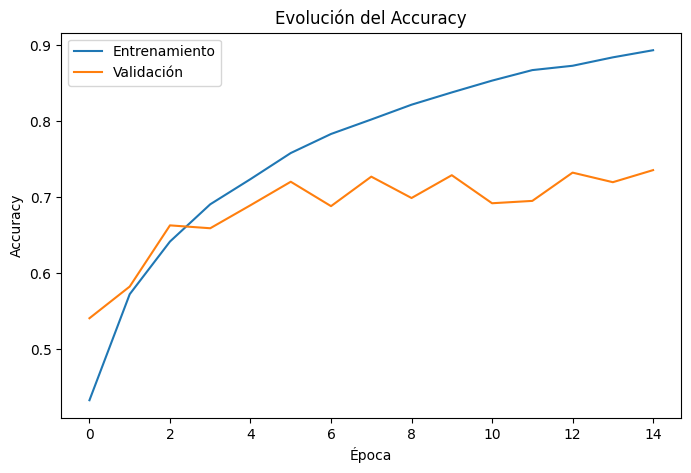

In [20]:
plt.figure(figsize=(8, 5))

plt.plot(
    historial.history["accuracy"],
    label="Entrenamiento"
)

plt.plot(
    historial.history["val_accuracy"],
    label="Validación"
)

plt.title("Evolución del Accuracy")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

### Interpretación del Accuracy durante el entrenamiento

El comportamiento de las curvas muestra que la Red Neuronal Convolucional aprende progresivamente las características presentes en las imágenes de entrenamiento.

El Accuracy de entrenamiento aumentó desde aproximadamente **43.27 % en la primera época hasta 89.32 % en la época 15**.

El Accuracy de validación también mejoró, aunque de manera más irregular. Su valor más alto fue de **73.55 % en la época 15**.

A partir de las primeras épocas comienza a observarse una diferencia creciente entre el desempeño de entrenamiento y validación. Al finalizar el entrenamiento existe una diferencia de aproximadamente **15.77 puntos porcentuales** entre ambos conjuntos.

Esta separación indica que el modelo comienza a especializarse cada vez más en las imágenes de entrenamiento y presenta señales de **sobreajuste**. Aunque continúa mejorando sobre los datos utilizados para aprender, dicha mejora no se refleja en la misma proporción sobre las imágenes de validación.

## 4.8 Evolución de la función de pérdida

Además del Accuracy se analizará la evolución de la función de pérdida.

Un valor menor de `loss` indica que las predicciones generadas por el modelo se encuentran más próximas a las etiquetas correctas.

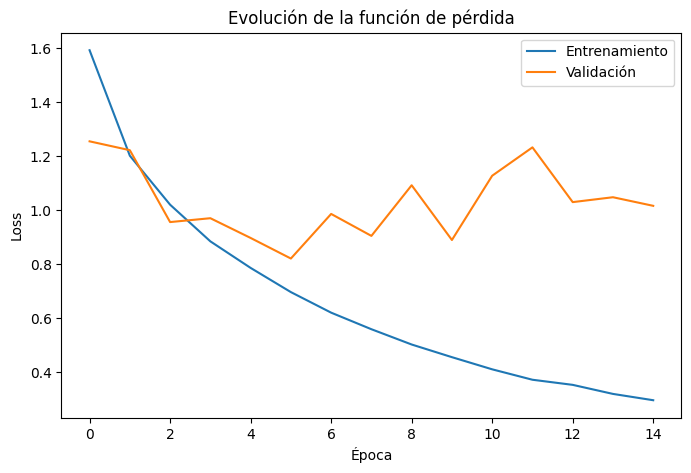

In [21]:
plt.figure(figsize=(8, 5))

plt.plot(
    historial.history["loss"],
    label="Entrenamiento"
)

plt.plot(
    historial.history["val_loss"],
    label="Validación"
)

plt.title("Evolución de la función de pérdida")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()

plt.show()

### Interpretación de la función de pérdida

La pérdida de entrenamiento disminuyó de manera constante durante las 15 épocas, pasando de aproximadamente **1.5927 a 0.2966**, lo cual demuestra que el modelo fue ajustándose cada vez mejor a las imágenes utilizadas durante el entrenamiento.

Sin embargo, la pérdida de validación no siguió el mismo comportamiento. Su valor mínimo fue de **0.8213 en la época 6**. Después de este punto comenzó a presentar diferentes aumentos y terminó en **1.0165**.

Este comportamiento constituye otra señal de **sobreajuste**. Después de aproximadamente seis épocas, la red continúa reduciendo considerablemente su error sobre los datos de entrenamiento, pero esa mejora ya no se reproduce de forma consistente en el conjunto de validación.

Esto sugiere que técnicas como Early Stopping, aumento de datos o una regularización adicional podrían utilizarse en futuras versiones del modelo para mejorar su capacidad de generalización.

# 5. Evaluación

Después del entrenamiento, el modelo será evaluado utilizando las **10,000 imágenes del conjunto de prueba**.

Estas imágenes no fueron utilizadas para actualizar los parámetros de la red ni para observar su comportamiento durante el entrenamiento.

Por esta razón proporcionan una evaluación independiente del modelo.

In [22]:
loss_test, accuracy_test = modelo.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(
    f"Loss en prueba: {loss_test:.4f}"
)

print(
    f"Accuracy en prueba: {accuracy_test:.4f}"
)

print(
    f"Accuracy en porcentaje: {accuracy_test:.2%}"
)

Loss en prueba: 1.0427
Accuracy en prueba: 0.7375
Accuracy en porcentaje: 73.75%


## 5.1 Predicciones sobre imágenes de prueba

La red generará una distribución de probabilidades para cada imagen.

La categoría con la probabilidad más alta será utilizada como predicción final.

In [23]:
probabilidades = modelo.predict(
    X_test,
    verbose=0
)

y_pred = np.argmax(
    probabilidades,
    axis=1
)

print("Cantidad de predicciones:", len(y_pred))

Cantidad de predicciones: 10000


In [24]:
resultados = pd.DataFrame({
    "Real": y_test[:20],
    "Predicción": y_pred[:20],
    "Clase_real": [
        nombres_clases[i]
        for i in y_test[:20]
    ],
    "Clase_predicha": [
        nombres_clases[i]
        for i in y_pred[:20]
    ]
})

resultados

,Real,Predicción,Clase_real,Clase_predicha
0,3,3,Gato,Gato
1,8,8,Barco,Barco
2,8,8,Barco,Barco
3,0,0,Avión,Avión
4,6,6,Rana,Rana
5,6,6,Rana,Rana
6,1,1,Automóvil,Automóvil
7,6,4,Rana,Venado
8,3,3,Gato,Gato
9,1,1,Automóvil,Automóvil


## 5.2 Verificación del Accuracy

Se calculará también el Accuracy mediante Scikit-learn para verificar el resultado obtenido durante la evaluación de TensorFlow.

In [25]:
from sklearn.metrics import accuracy_score

accuracy_sklearn = accuracy_score(
    y_test,
    y_pred
)

print(
    f"Accuracy con Scikit-learn: "
    f"{accuracy_sklearn:.4f}"
)

print(
    f"Porcentaje: "
    f"{accuracy_sklearn:.2%}"
)

Accuracy con Scikit-learn: 0.7375
Porcentaje: 73.75%


## 5.3 Reporte de clasificación

Además del Accuracy general se calcularán métricas para cada una de las diez categorías.

El reporte incluye:

- **Precision:** de las imágenes clasificadas como determinada categoría, cuántas pertenecían realmente a ella.
- **Recall:** de todas las imágenes que realmente pertenecían a una categoría, cuántas fueron identificadas.
- **F1-score:** medida que combina Precision y Recall.
- **Support:** cantidad real de imágenes pertenecientes a cada categoría.

In [26]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=nombres_clases,
        digits=4
    )
)

              precision    recall  f1-score   support

       Avión     0.7628    0.7910    0.7766      1000
   Automóvil     0.8808    0.8200    0.8493      1000
         Ave     0.6034    0.6800    0.6394      1000
        Gato     0.5095    0.6150    0.5573      1000
      Venado     0.7320    0.6390    0.6823      1000
       Perro     0.6996    0.5450    0.6127      1000
        Rana     0.8176    0.8070    0.8123      1000
     Caballo     0.8363    0.7410    0.7858      1000
       Barco     0.8472    0.8480    0.8476      1000
      Camión     0.7585    0.8890    0.8186      1000

    accuracy                         0.7375     10000
   macro avg     0.7448    0.7375    0.7382     10000
weighted avg     0.7448    0.7375    0.7382     10000



In [27]:
from sklearn.metrics import (
    precision_recall_fscore_support
)

precision_clase, recall_clase, f1_clase, soporte = (
    precision_recall_fscore_support(
        y_test,
        y_pred,
        labels=range(10)
    )
)

metricas_clases = pd.DataFrame({
    "Clase": nombres_clases,
    "Precision": precision_clase,
    "Recall": recall_clase,
    "F1-score": f1_clase,
    "Cantidad": soporte
})

metricas_clases[
    ["Precision", "Recall", "F1-score"]
] = metricas_clases[
    ["Precision", "Recall", "F1-score"]
].round(4)

metricas_clases

,Clase,Precision,Recall,F1-score,Cantidad
0,Avión,0.7628,0.791,0.7766,1000
1,Automóvil,0.8808,0.820,0.8493,1000
2,Ave,0.6034,0.680,0.6394,1000
3,Gato,0.5095,0.615,0.5573,1000
4,Venado,0.7320,0.639,0.6823,1000
5,Perro,0.6996,0.545,0.6127,1000
6,Rana,0.8176,0.807,0.8123,1000
7,Caballo,0.8363,0.741,0.7858,1000
8,Barco,0.8472,0.848,0.8476,1000
9,Camión,0.7585,0.889,0.8186,1000


In [28]:
mejor_clase = metricas_clases.loc[
    metricas_clases["F1-score"].idxmax()
]

peor_clase = metricas_clases.loc[
    metricas_clases["F1-score"].idxmin()
]

print("Clase con mayor F1-score:")
print(mejor_clase)

print("\nClase con menor F1-score:")
print(peor_clase)

Clase con mayor F1-score:
Clase        Automóvil
Precision       0.8808
Recall            0.82
F1-score        0.8493
Cantidad          1000
Name: 1, dtype: object

Clase con menor F1-score:
Clase          Gato
Precision    0.5095
Recall        0.615
F1-score     0.5573
Cantidad       1000
Name: 3, dtype: object


### Interpretación del reporte de clasificación

El modelo obtuvo un **Accuracy general de 73.75 %**, pero su desempeño no es igual para todas las categorías.

La categoría con mayor F1-score fue **Automóvil**, con un valor de **0.8493**. Esta clase presentó además una Precision de **88.08 %** y un Recall de **82.00 %**, lo que indica que el modelo logra identificar los automóviles con bastante efectividad.

Otras categorías con buenos resultados fueron **Barco**, con un F1-score de **0.8476**, **Camión**, con **0.8186**, y **Rana**, con **0.8123**.

La categoría que presentó mayor dificultad fue **Gato**, con un F1-score de solamente **0.5573**. En esta clase la Precision fue de **50.95 %** y el Recall de **61.50 %**.

También se observa un desempeño relativamente bajo en las categorías **Perro**, con un F1-score de **0.6127**, y **Ave**, con **0.6394**.

Estos resultados muestran que la CNN identifica con mayor facilidad algunas categorías con características visuales más diferenciables, mientras que presenta más dificultades cuando los objetos comparten formas o características semejantes.

## 5.4 Matriz de confusión

La matriz de confusión permitirá analizar qué categorías fueron clasificadas correctamente y cuáles se confunden con mayor frecuencia.

Cada fila representa la categoría real y cada columna representa la categoría predicha por el modelo.

Los valores ubicados sobre la diagonal principal corresponden a clasificaciones correctas.

In [29]:
from sklearn.metrics import confusion_matrix

matriz_confusion = confusion_matrix(
    y_test,
    y_pred
)

matriz_confusion

array([[791,  12,  47,  37,  13,   5,   7,   7,  37,  44],
       [ 16, 820,   7,   9,   2,   0,   5,   0,  24, 117],
       [ 71,   7, 680,  65,  54,  35,  38,  23,  16,  11],
       [ 23,   7,  98, 615,  46, 105,  54,  17,  12,  23],
       [ 25,   4, 100,  80, 639,  29,  44,  54,  20,   5],
       [ 14,   5,  83, 241,  34, 545,  22,  39,   4,  13],
       [  6,   7,  55,  63,  20,  17, 807,   4,  15,   6],
       [ 23,   4,  40,  70,  58,  35,   5, 741,   5,  19],
       [ 46,  23,   8,  18,   5,   5,   1,   1, 848,  45],
       [ 22,  42,   9,   9,   2,   3,   4,   0,  20, 889]])

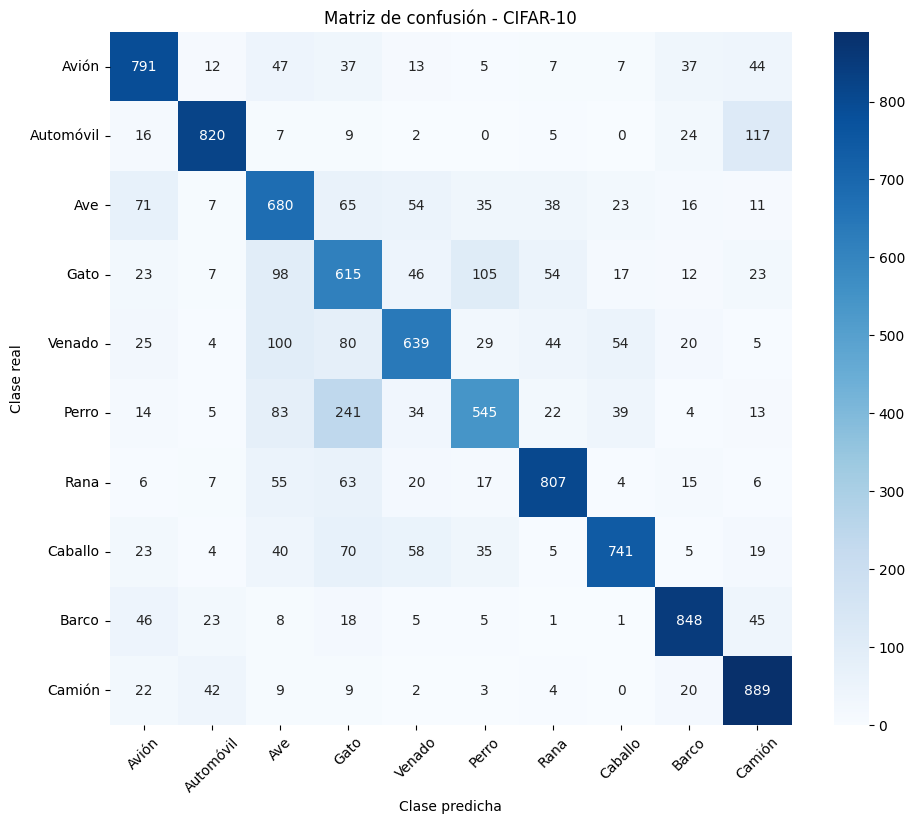

In [30]:
plt.figure(figsize=(11, 9))

sns.heatmap(
    matriz_confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nombres_clases,
    yticklabels=nombres_clases
)

plt.title("Matriz de confusión - CIFAR-10")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.show()

## 5.5 Identificación de las confusiones más frecuentes

Se analizará la matriz de confusión para identificar qué pares de categorías diferentes presentan la mayor cantidad de errores.

In [31]:
matriz_sin_diagonal = matriz_confusion.copy()

np.fill_diagonal(
    matriz_sin_diagonal,
    0
)

errores_clases = []

for real in range(10):
    for predicha in range(10):
        if real != predicha:
            errores_clases.append({
                "Clase real": nombres_clases[real],
                "Predicción": nombres_clases[predicha],
                "Errores": matriz_sin_diagonal[
                    real,
                    predicha
                ]
            })

errores_clases = pd.DataFrame(
    errores_clases
)

errores_clases = errores_clases.sort_values(
    "Errores",
    ascending=False
)

errores_clases.head(10)

,Clase real,Predicción,Errores
48,Perro,Gato,241
17,Automóvil,Camión,117
31,Gato,Perro,105
38,Venado,Ave,100
29,Gato,Ave,98
47,Perro,Ave,83
39,Venado,Gato,80
18,Ave,Avión,71
66,Caballo,Gato,70
20,Ave,Gato,65


### Interpretación de las principales confusiones

La matriz de confusión muestra que el error más frecuente del modelo ocurre cuando una imagen que realmente corresponde a un **Perro** es clasificada como **Gato**. Esto ocurrió en **241 imágenes**.

También existe confusión en el sentido contrario: **105 imágenes de gatos fueron clasificadas como perros**.

Este resultado ayuda a explicar por qué las categorías Gato y Perro presentan algunos de los F1-score más bajos del modelo. Ambas clases corresponden a animales que pueden compartir características visuales relacionadas con forma, textura, postura y fondo, mientras que la baja resolución de 32 × 32 píxeles limita la cantidad de detalle disponible.

Otra confusión importante se presenta entre **Automóvil y Camión**, con **117 automóviles clasificados como camiones**.

También se encontraron confusiones entre **Venado y Ave**, con 100 casos, y entre **Gato y Ave**, con 98 casos.

Por lo tanto, la matriz de confusión permite observar que los errores no se distribuyen de manera uniforme, sino que existen determinados pares de categorías que resultan considerablemente más difíciles para la red neuronal.

## 5.6 Ejemplos de imágenes clasificadas correctamente

A continuación se seleccionarán diferentes imágenes del conjunto de prueba que fueron clasificadas correctamente.

En cada imagen se mostrará:

- Clase real.
- Clase predicha.
- Probabilidad asignada a la predicción.

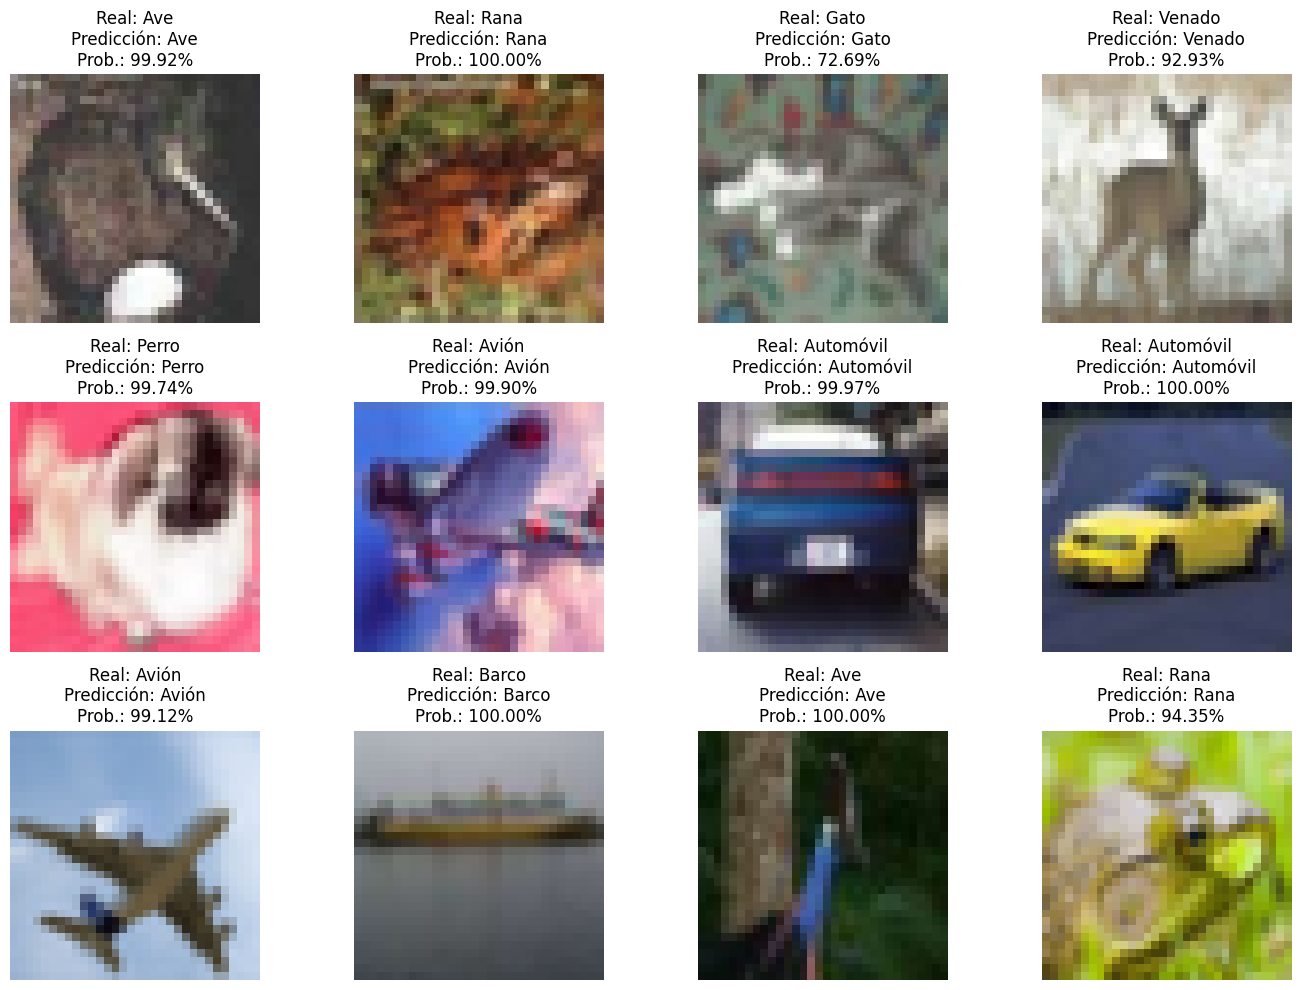

In [32]:
indices_correctos = np.where(
    y_pred == y_test
)[0]

rng = np.random.default_rng(42)

muestra_correctos = rng.choice(
    indices_correctos,
    size=12,
    replace=False
)

plt.figure(figsize=(14, 10))

for posicion, indice in enumerate(
    muestra_correctos
):

    plt.subplot(3, 4, posicion + 1)

    plt.imshow(X_test[indice])

    clase_real = nombres_clases[
        y_test[indice]
    ]

    clase_predicha = nombres_clases[
        y_pred[indice]
    ]

    confianza = probabilidades[
        indice,
        y_pred[indice]
    ]

    plt.title(
        f"Real: {clase_real}\n"
        f"Predicción: {clase_predicha}\n"
        f"Prob.: {confianza:.2%}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

Los ejemplos muestran imágenes en las que la categoría con mayor probabilidad coincidió con la etiqueta real.

La probabilidad mostrada representa el nivel de confianza asignado por la salida `softmax` del modelo a la categoría seleccionada.

Es importante recordar que una probabilidad elevada no garantiza necesariamente que una clasificación sea correcta; únicamente representa el nivel de confianza generado por el modelo.

## 5.7 Ejemplos de imágenes clasificadas incorrectamente

También se analizarán imágenes en las que la predicción no coincidió con la etiqueta real.

Observar directamente estos errores permite comprender mejor las dificultades que enfrenta la red neuronal.

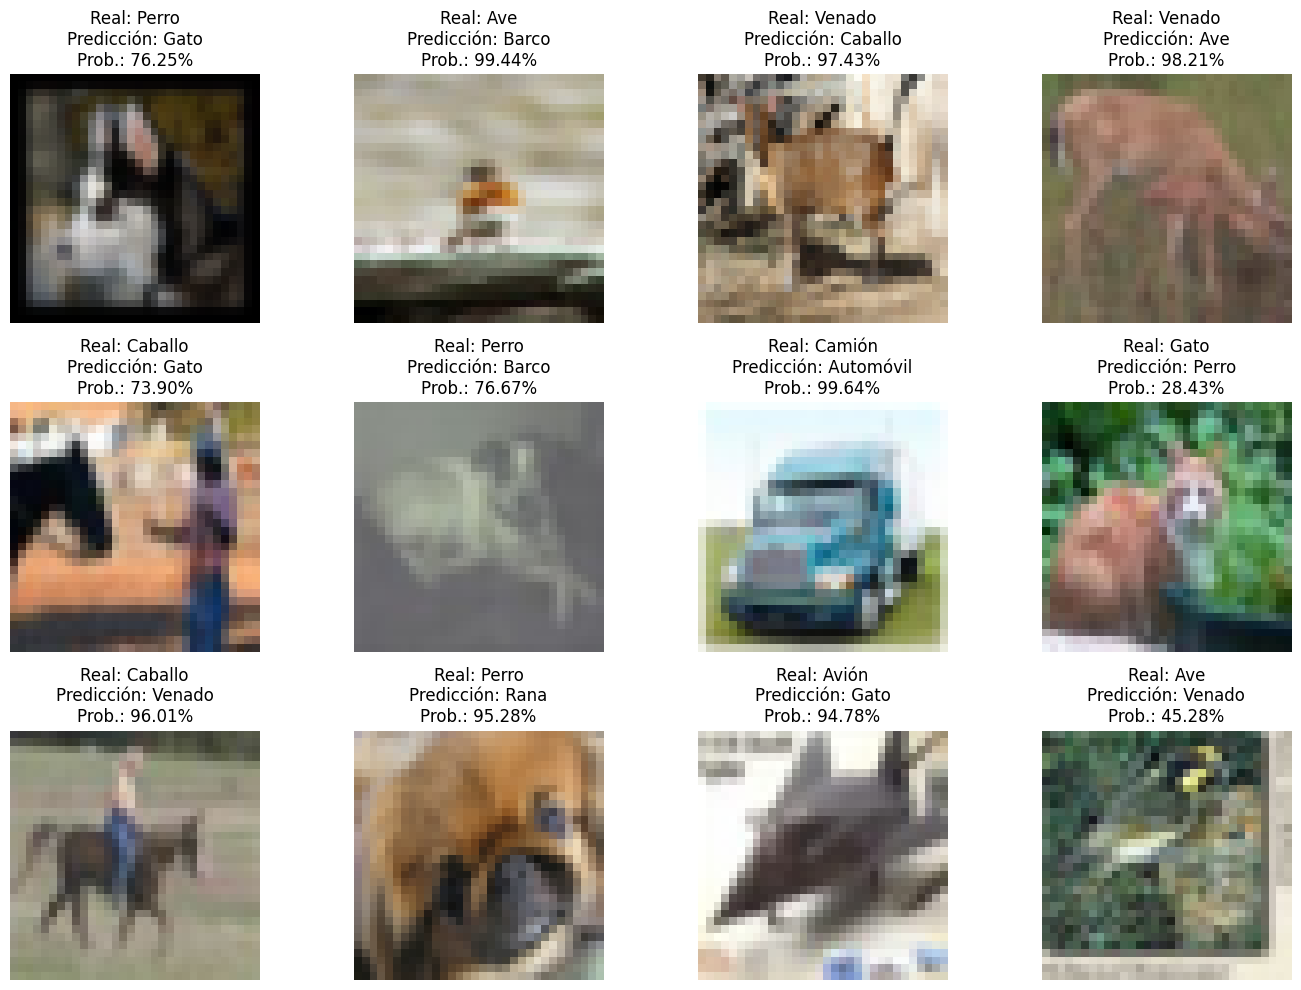

In [33]:
indices_incorrectos = np.where(
    y_pred != y_test
)[0]

muestra_errores = rng.choice(
    indices_incorrectos,
    size=12,
    replace=False
)

plt.figure(figsize=(14, 10))

for posicion, indice in enumerate(
    muestra_errores
):

    plt.subplot(3, 4, posicion + 1)

    plt.imshow(X_test[indice])

    clase_real = nombres_clases[
        y_test[indice]
    ]

    clase_predicha = nombres_clases[
        y_pred[indice]
    ]

    confianza = probabilidades[
        indice,
        y_pred[indice]
    ]

    plt.title(
        f"Real: {clase_real}\n"
        f"Predicción: {clase_predicha}\n"
        f"Prob.: {confianza:.2%}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

Las imágenes clasificadas incorrectamente permiten observar que algunas confusiones pueden ser comprensibles incluso visualmente debido a la baja resolución de CIFAR-10.

Una imagen de 32 × 32 píxeles contiene relativamente poca información visual en comparación con fotografías de mayor resolución.

Además, algunos objetos pueden aparecer con diferentes posiciones, colores, fondos y tamaños.

El análisis de estos errores permite conocer las limitaciones del modelo y detectar clases que podrían requerir una arquitectura más avanzada o técnicas adicionales de entrenamiento.

## 5.8 Predicciones incorrectas con mayor confianza

Un caso particularmente interesante ocurre cuando el modelo realiza una clasificación incorrecta pero asigna una probabilidad elevada a su respuesta.

Se identificarán algunos de estos ejemplos.

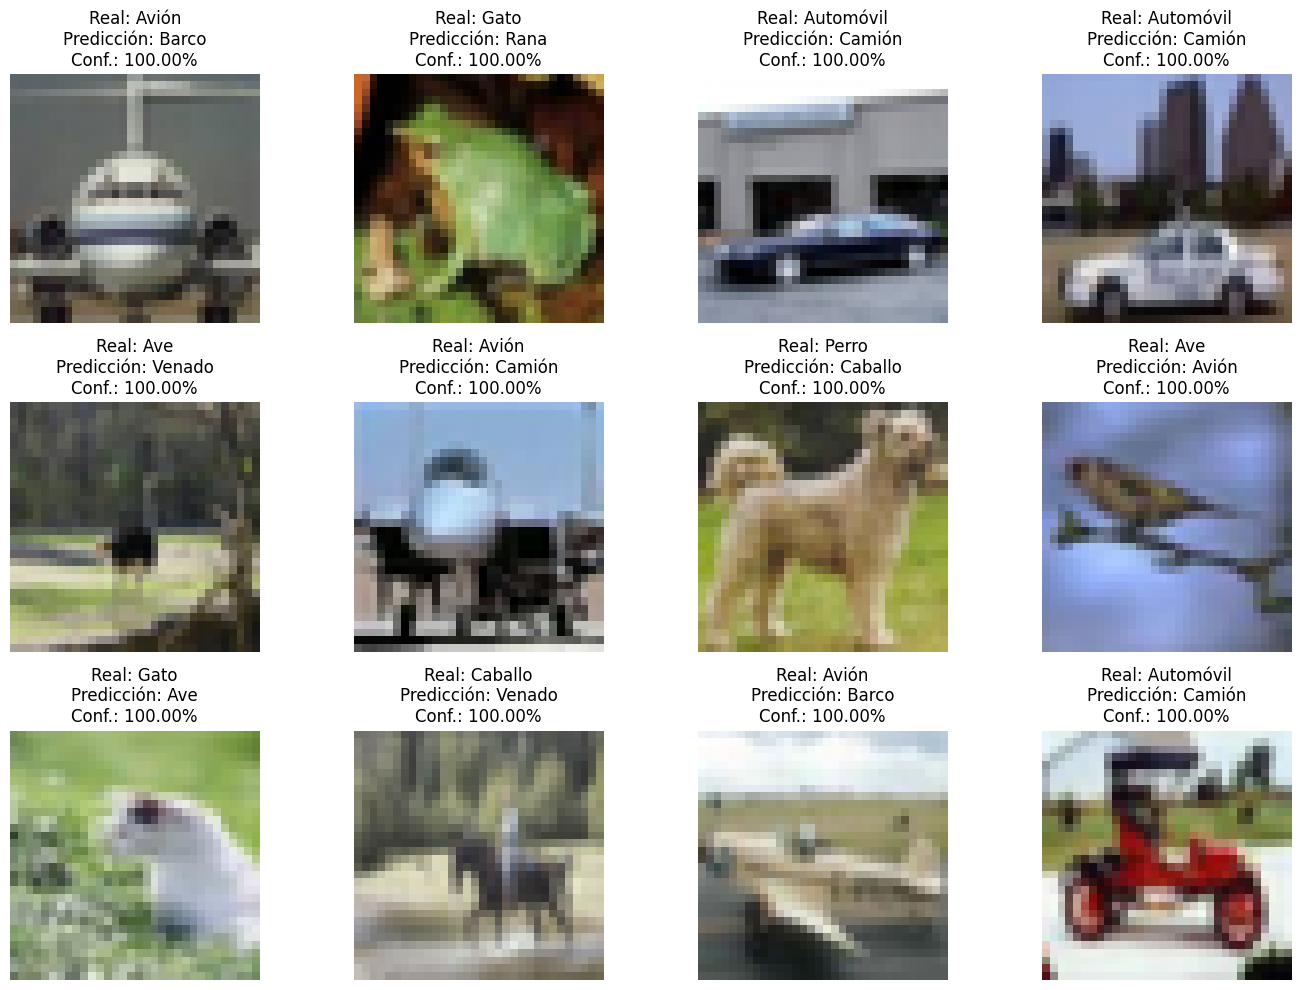

In [34]:
confianza_errores = probabilidades[
    indices_incorrectos,
    y_pred[indices_incorrectos]
]

orden = np.argsort(
    confianza_errores
)[::-1]

errores_alta_confianza = (
    indices_incorrectos[
        orden[:12]
    ]
)

plt.figure(figsize=(14, 10))

for posicion, indice in enumerate(
    errores_alta_confianza
):

    plt.subplot(3, 4, posicion + 1)

    plt.imshow(X_test[indice])

    real = nombres_clases[
        y_test[indice]
    ]

    predicha = nombres_clases[
        y_pred[indice]
    ]

    confianza = probabilidades[
        indice,
        y_pred[indice]
    ]

    plt.title(
        f"Real: {real}\n"
        f"Predicción: {predicha}\n"
        f"Conf.: {confianza:.2%}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

Estos ejemplos muestran una característica importante de los modelos de aprendizaje profundo: una predicción puede ser incorrecta incluso cuando el modelo presenta un nivel de confianza elevado.

Por esta razón, las probabilidades producidas por una red neuronal no deben interpretarse automáticamente como una garantía de que su respuesta sea correcta.

Analizar este tipo de errores resulta especialmente importante cuando los modelos se utilizan en aplicaciones reales.

## 5.9 Resumen cuantitativo de los resultados

La siguiente celda generará un resumen utilizando los resultados reales obtenidos durante la ejecución del notebook.

In [35]:
total_correctas = np.sum(
    y_pred == y_test
)

total_incorrectas = np.sum(
    y_pred != y_test
)

print("RESUMEN DE LA EVALUACIÓN\n")

print(
    f"Imágenes evaluadas: "
    f"{len(y_test):,}"
)

print(
    f"Clasificaciones correctas: "
    f"{total_correctas:,}"
)

print(
    f"Clasificaciones incorrectas: "
    f"{total_incorrectas:,}"
)

print(
    f"Accuracy en prueba: "
    f"{accuracy_test:.2%}"
)

print(
    f"Loss en prueba: "
    f"{loss_test:.4f}"
)

print(
    f"\nClase con mayor F1-score: "
    f"{mejor_clase['Clase']} "
    f"({mejor_clase['F1-score']:.4f})"
)

print(
    f"Clase con menor F1-score: "
    f"{peor_clase['Clase']} "
    f"({peor_clase['F1-score']:.4f})"
)

RESUMEN DE LA EVALUACIÓN

Imágenes evaluadas: 10,000
Clasificaciones correctas: 7,375
Clasificaciones incorrectas: 2,625
Accuracy en prueba: 73.75%
Loss en prueba: 1.0427

Clase con mayor F1-score: Automóvil (0.8493)
Clase con menor F1-score: Gato (0.5573)


## 5.10 Comportamiento durante el entrenamiento

Se identificarán las épocas en las que el modelo obtuvo el mejor Accuracy y la menor pérdida sobre el conjunto de validación.

In [36]:
mejor_epoca_accuracy = (
    np.argmax(
        historial.history["val_accuracy"]
    ) + 1
)

mejor_accuracy_val = max(
    historial.history["val_accuracy"]
)

mejor_epoca_loss = (
    np.argmin(
        historial.history["val_loss"]
    ) + 1
)

mejor_loss_val = min(
    historial.history["val_loss"]
)

print(
    f"Mejor Accuracy de validación: "
    f"{mejor_accuracy_val:.2%}"
)

print(
    f"Época correspondiente: "
    f"{mejor_epoca_accuracy}"
)

print(
    f"\nMenor Loss de validación: "
    f"{mejor_loss_val:.4f}"
)

print(
    f"Época correspondiente: "
    f"{mejor_epoca_loss}"
)

Mejor Accuracy de validación: 73.55%
Época correspondiente: 15

Menor Loss de validación: 0.8213
Época correspondiente: 6


## 5.11 ¿El modelo cumple con el objetivo?

El modelo cumple con el objetivo académico establecido, ya que fue capaz de aprender características visuales directamente a partir de las imágenes y clasificar datos que no participaron durante su entrenamiento.

La Red Neuronal Convolucional obtuvo un **Accuracy de 73.75 % sobre las 10,000 imágenes de prueba**, lo que representa **7,375 clasificaciones correctas y 2,625 incorrectas**.

Este resultado demuestra que la arquitectura utilizada logró aprender patrones relevantes de las imágenes de CIFAR-10. Sin embargo, el análisis por categorías muestra que el desempeño no es uniforme.

Clases como Automóvil, Barco, Camión y Rana presentan mejores resultados, mientras que Gato, Perro y Ave representan una mayor dificultad para el modelo.

También se identificaron señales de sobreajuste durante el entrenamiento. El Accuracy de entrenamiento alcanzó aproximadamente **89.32 %**, mientras que el de validación terminó en **73.55 %**. Además, la menor pérdida de validación ocurrió en la época 6 y posteriormente comenzó a aumentar mientras la pérdida de entrenamiento continuaba disminuyendo.

Por lo tanto, el modelo puede considerarse una solución funcional para el problema educativo planteado, aunque todavía existe margen de mejora en su capacidad de generalización y en la clasificación de determinadas categorías.

## 5.12 Limitaciones

El modelo desarrollado presenta diferentes limitaciones que deben considerarse al interpretar sus resultados.

**Baja resolución de las imágenes:** CIFAR-10 utiliza imágenes de solamente 32 × 32 píxeles. Esto puede dificultar la identificación de algunos objetos.

**Similitud entre categorías:** algunas clases presentan características visuales semejantes. Por ejemplo, gatos y perros pertenecen a categorías distintas, pero pueden compartir formas, colores y fondos similares.

**Arquitectura relativamente sencilla:** la CNN utilizada permite demostrar los fundamentos de las redes convolucionales, pero existen arquitecturas considerablemente más profundas y avanzadas.

**Cantidad limitada de épocas:** el entrenamiento se realizó durante 15 épocas para mantener un equilibrio entre tiempo de ejecución y aprendizaje.

**Variaciones dentro de las imágenes:** los objetos pueden aparecer en diferentes posiciones, tamaños, colores y fondos.

**Sobreajuste:** durante el entrenamiento se observaron señales claras de sobreajuste. El Accuracy de entrenamiento alcanzó **89.32 %**, mientras que el Accuracy de validación terminó en **73.55 %**. Además, la pérdida de validación obtuvo su mejor valor en la época 6 y posteriormente aumentó, mientras la pérdida de entrenamiento continuó disminuyendo. Esto indica que el modelo fue especializándose progresivamente en las imágenes de entrenamiento sin obtener una mejora equivalente en su capacidad para generalizar.

Estas limitaciones muestran que el desempeño de una red neuronal depende tanto de la arquitectura como de las características del conjunto de datos y del proceso de entrenamiento.

## 5.13 Posibles mejoras

Los resultados obtenidos muestran que una de las principales áreas de mejora consiste en reducir el sobreajuste y aumentar la capacidad de generalización del modelo.

Una primera estrategia sería utilizar **Early Stopping**, deteniendo automáticamente el entrenamiento cuando la pérdida de validación deje de mejorar. En este experimento, el menor `val_loss` se obtuvo en la **época 6**, por lo que continuar el entrenamiento hasta la época 15 permitió mejorar el Accuracy de entrenamiento, pero también incrementó la diferencia respecto al conjunto de validación.

Otra estrategia especialmente apropiada para imágenes sería utilizar **Data Augmentation**, generando variaciones de las imágenes mediante pequeñas traslaciones, rotaciones o inversiones horizontales. Esto permitiría que el modelo observe una mayor diversidad de ejemplos durante el entrenamiento.

También podrían probarse:

- Arquitecturas convolucionales más profundas.
- Diferentes cantidades de filtros.
- Mayor regularización mediante Dropout.
- Ajustes de la tasa de aprendizaje.
- Diferentes tamaños de lote.
- Transfer Learning mediante modelos previamente entrenados.
- Búsqueda sistemática de hiperparámetros.

También sería importante estudiar específicamente las categorías que presentaron mayores dificultades, principalmente Gato, Perro y Ave, debido a que concentran una parte importante de los errores observados.

# Conclusiones

El desarrollo de este proyecto permitió aplicar las cinco fases de trabajo de CRISP-DM a un problema de clasificación multiclase de imágenes utilizando aprendizaje profundo.

Durante la **Comprensión del problema** se estableció como objetivo desarrollar un sistema capaz de clasificar imágenes automáticamente en una de diez categorías diferentes.

En la **Comprensión de los datos** se analizó el conjunto CIFAR-10, compuesto por **60,000 imágenes RGB de 32 × 32 píxeles** distribuidas de manera equilibrada entre diez clases. Cada categoría contiene 6,000 imágenes en total, de las cuales 5,000 pertenecen originalmente al conjunto de entrenamiento y 1,000 al conjunto de prueba.

Durante la **Preparación de los datos**, las 50,000 imágenes originales de entrenamiento fueron divididas en **40,000 imágenes para entrenamiento y 10,000 para validación**, manteniendo además las **10,000 imágenes de prueba** proporcionadas por CIFAR-10. Los valores de los píxeles también fueron normalizados del intervalo de 0–255 al intervalo de 0–1.

En la fase de **Modelado** se construyó una Red Neuronal Convolucional mediante TensorFlow/Keras. La arquitectura utilizó tres bloques convolucionales con 32, 64 y 128 filtros, además de BatchNormalization, MaxPooling2D, una capa Dense, Dropout y una capa final Softmax de diez neuronas.

Después de 15 épocas de entrenamiento, el modelo fue evaluado utilizando las 10,000 imágenes del conjunto de prueba. Se obtuvo un **Accuracy de 73.75 % y un Loss de 1.0427**, lo que corresponde a **7,375 imágenes clasificadas correctamente y 2,625 clasificadas incorrectamente**.

El análisis individual de las categorías mostró diferencias importantes. **Automóvil** obtuvo el mejor F1-score, con **0.8493**, mientras que **Gato** presentó el menor resultado, con **0.5573**. También se observaron resultados favorables para Barco, Camión y Rana.

La matriz de confusión permitió identificar que uno de los principales problemas del modelo es distinguir entre algunas categorías visualmente semejantes. El error más frecuente ocurrió cuando imágenes de **Perros fueron clasificadas como Gatos**, con 241 casos. También se encontraron 105 Gatos clasificados como Perros y 117 Automóviles clasificados como Camiones.

Durante el entrenamiento también se identificaron señales de **sobreajuste**. El Accuracy de entrenamiento alcanzó **89.32 %**, mientras que el de validación terminó en **73.55 %**. La pérdida de validación obtuvo su mejor valor, **0.8213**, en la época 6, pero posteriormente aumentó mientras la pérdida de entrenamiento continuó disminuyendo.

A pesar de estas limitaciones, el proyecto demuestra que una Red Neuronal Convolucional puede aprender automáticamente características visuales a partir de los píxeles y utilizarlas para resolver un problema de clasificación multiclase.

El ejercicio también permitió comprender que evaluar una red neuronal no consiste únicamente en observar el Accuracy final. Es necesario analizar las curvas de entrenamiento, el comportamiento por categoría, la matriz de confusión y los errores específicos para comprender realmente las fortalezas y limitaciones del modelo.

Como trabajo futuro, sería recomendable utilizar Data Augmentation, Early Stopping, mayor regularización y diferentes arquitecturas con el objetivo de disminuir el sobreajuste y mejorar especialmente la clasificación de las categorías que presentan mayores dificultades.

# Referencias

- Krizhevsky, A. *CIFAR-10 and CIFAR-100 Datasets*. University of Toronto.  
  https://www.cs.toronto.edu/~kriz/cifar.html

- Keras. *CIFAR10 small images classification dataset*. Keras API Documentation.  
  https://keras.io/api/datasets/cifar10/

- TensorFlow. *tf.keras.datasets.cifar10.load_data*. TensorFlow Documentation.  
  https://www.tensorflow.org/api_docs/python/tf/keras/datasets/cifar10/load_data

- TensorFlow. *Keras: Deep Learning API*.  
  https://www.tensorflow.org/guide/keras

- Scikit-learn Developers. *Scikit-learn User Guide*.  
  https://scikit-learn.org/stable/user_guide.html

- Matplotlib Development Team. *Matplotlib Documentation*.  
  https://matplotlib.org/stable/

- Seaborn Development Team. *Seaborn Documentation*.  
  https://seaborn.pydata.org/